# Iris Classification with k-Nearest Neighbors
Author: Manuel Eugenio Morocho Cayamcela, PhD

## Introduction
Use supervised learning to classify 150 Iris flowers into three species from four measurements: sepal length, sepal width, petal length, and petal width (in centimeters). This lesson covers loading data, exploration, preprocessing, training a k-nearest neighbors (k-NN) classifier, saving the model, and evaluating predictions.

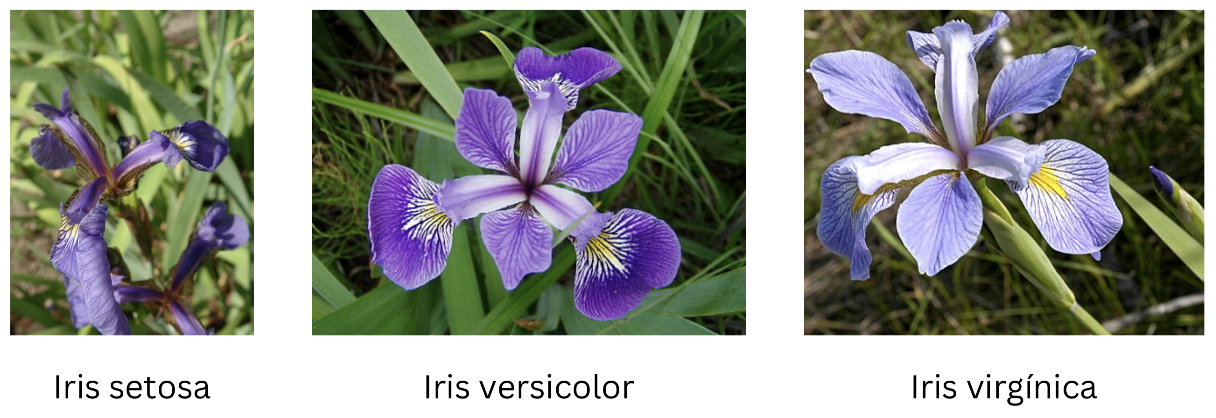

## Setup
If needed, install the packages once with `%pip install pandas matplotlib seaborn scikit-learn joblib`. Restart the kernel after installation if requested.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## Load the Iris dataset
Read the Iris CSV directly from GitHub using pandas. An internet connection is required.

In [2]:
github_url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/iris.csv"
iris = pd.read_csv(github_url)

## Explore and prepare the data
Run each cell separately and inspect its output before continuing.

Preview the first five records.

In [3]:
iris.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Inspect column types and non-null counts to identify missing values.

In [4]:
iris.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


Summarize the numeric columns.

In [5]:
iris.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Count the examples of each species.

In [6]:
iris["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

Remove `Id`: it identifies records rather than measuring flowers.

In [7]:
iris = iris.drop(columns="Id")

## Visualize the measurements
Compare sepal and petal measurements by species. Setosa is particularly distinct in petal measurements; versicolor and virginica overlap more. These plots help assess whether the measurements can separate the classes.

### Sepal measurements

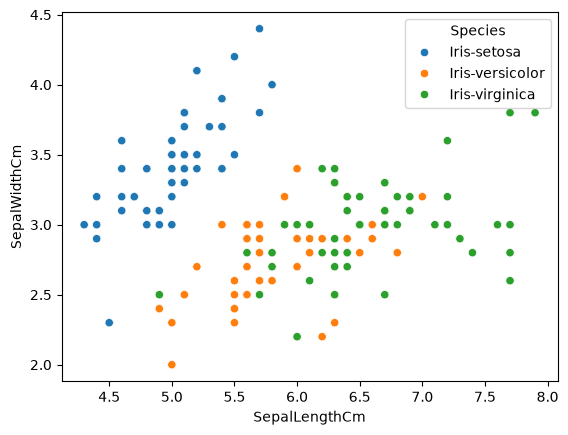

In [8]:
sns.scatterplot(data=iris, x="SepalLengthCm", y="SepalWidthCm", hue="Species")
plt.show()

### Petal measurements

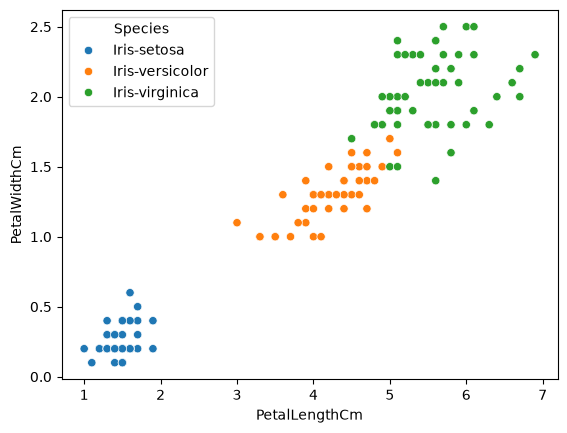

In [9]:
sns.scatterplot(data=iris, x="PetalLengthCm", y="PetalWidthCm", hue="Species")
plt.show()

The pair plot compares every pair of measurements. Histograms on the diagonal show each feature's distribution.

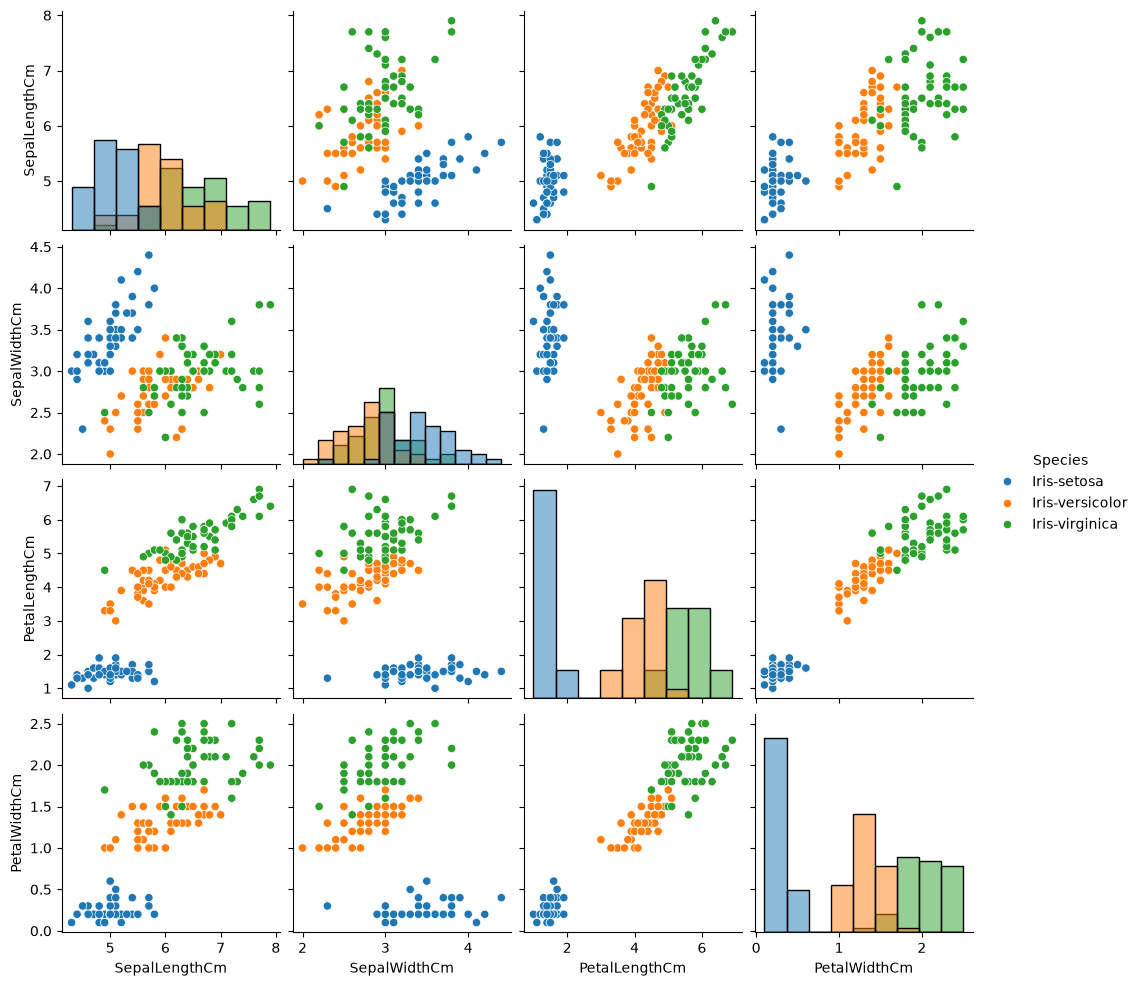

In [10]:
sns.pairplot(iris, hue="Species", diag_kind="hist")
plt.show()

## Prepare training and test sets
Separate the four predictors (`X`) from the species label (`y`). Reserve 20% of the data for testing. Stratification preserves class proportions, and a fixed random seed makes the split reproducible. Keep the test set out of model fitting.

In [11]:
# Isolate features
X = iris.drop(columns="Species")

# Isolate target variable
y = iris["Species"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Train the k-NN classifier
With `n_neighbors=5`, the classifier predicts a flower's species from the majority class among its five nearest training examples. Fit the model on the training set only.

In [12]:
from sklearn.neighbors import KNeighborsClassifier

classifier = KNeighborsClassifier(n_neighbors=5)
classifier.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Iris-setosa','Iris-versicolor','Iris-virginica']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


## Evaluate on unseen data
Predict the species of the held-out examples.

In [13]:
predictions = classifier.predict(X_test)

### Accuracy
Accuracy is the fraction of correctly classified test examples.

In [14]:
print(f"Test accuracy: {accuracy_score(y_test, predictions):.3f}")

Test accuracy: 1.000


### Classification report
The report summarizes each species:

- **Precision:** TP / (TP + FP), the fraction of predictions for that species that are correct.
- **Recall:** TP / (TP + FN), the fraction of actual flowers of that species correctly identified.
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** the number of true examples of that species in the test set.

Interpret the results generated below; scores can change with the split and model settings.

In [15]:
print(classification_report(y_test, predictions, zero_division=0))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00        10
 Iris-virginica       1.00      1.00      1.00        10

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



### Confusion matrix
Rows show actual classes and columns show predicted classes. Diagonal entries are correct predictions.

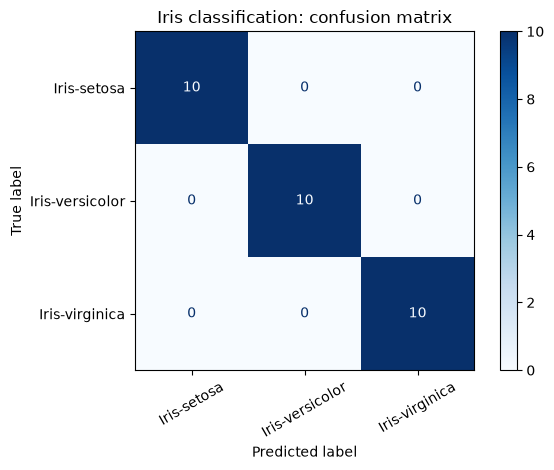

In [17]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=classifier.classes_, cmap="Blues"
)
plt.title("Iris classification: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Save and reload the trained model
Save the fitted classifier for reuse without retraining. Only load model files you trust. The file is written to the current working directory.

In [20]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [18]:
import joblib

model_path = Path("knn_model.pkl")
joblib.dump(classifier, model_path)

['knn_model.pkl']

In [ ]:
loaded_classifier = joblib.load(model_path)
loaded_classifier.predict(X_test.head())

## Activity: Data Preprocessing and Customer Classification with k-NN
### Objective
Explore a classification dataset, train k-NN, and select a suitable value of `k`. Work individually or in a group, share the work fairly, and justify your decisions.

### Where to find datasets
For this short activity, choose a small tabular dataset with a clearly documented categorical target. Prefer CSV files and numeric predictors so that data preparation remains manageable.

- [UCI Machine Learning Repository](https://archive.ics.uci.edu/): a useful starting point for classification datasets.
- [Kaggle Datasets](https://www.kaggle.com/datasets): browse datasets and select one with a documented target and downloadable tabular files. Check access requirements before choosing it.
- [Awesome Public Datasets on GitHub](https://github.com/awesomedata/awesome-public-datasets): a topic-based directory linking to datasets; check the original source for files and documentation.
- [Ecuador Open Data Portal — CSV datasets](https://www.datosabiertos.gob.ec/dataset/?res_format=CSV): explore Ecuadorian public data available in CSV format.
- [INEC Open Data Bank](https://aplicaciones3.ecuadorencifras.gob.ec/BIINEC-war/index.xhtml): find Ecuadorian statistical information and consult the accompanying documentation.
- [U.S. Government Open Data](https://data.gov/): search public datasets by topic or organization.

Government portals are useful for local or applied topics, but their tables may require more cleaning and may not have a ready-made classification target. Verify the target column and download format before committing to a dataset.

### Instructions
1. **Find and explore a dataset (10 minutes).** Load a classification dataset, inspect its structure, and clean or transform it as needed.

In [23]:
# Import the dataset
# Source: https://www.kaggle.com/code/kanncaa1/machine-learning-tutorial-for-beginners
data1 = pd.read_csv("column_3C_weka.csv")
data1.head()


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis,class
0,63.027817,22.552586,39.609117,40.475232,98.672917,-0.254400,Hernia
1,39.056951,10.060991,25.015378,28.995960,114.405425,4.564259,Hernia
2,68.832021,22.218482,50.092194,46.613539,105.985135,-3.530317,Hernia
3,69.297008,24.652878,44.311238,44.644130,101.868495,11.211523,Hernia
4,49.712859,9.652075,28.317406,40.060784,108.168725,7.918501,Hernia


In [28]:
data1['class'].unique()

<StringArray>
['Hernia', 'Spondylolisthesis', 'Normal']
Length: 3, dtype: str

In [24]:
data1.info()

<class 'pandas.DataFrame'>
RangeIndex: 310 entries, 0 to 309
Data columns (total 7 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   pelvic_incidence          310 non-null    float64
 1   pelvic_tilt               310 non-null    float64
 2   lumbar_lordosis_angle     310 non-null    float64
 3   sacral_slope              310 non-null    float64
 4   pelvic_radius             310 non-null    float64
 5   degree_spondylolisthesis  310 non-null    float64
 6   class                     310 non-null    str    
dtypes: float64(6), str(1)
memory usage: 17.1 KB


In [25]:
data1.describe()

,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,degree_spondylolisthesis
count,310.000000,310.000000,310.000000,310.000000,310.000000,310.000000
mean,60.496653,17.542822,51.930930,42.953831,117.920655,26.296694
std,17.236520,10.008330,18.554064,13.423102,13.317377,37.559027
min,26.147921,-6.554948,14.000000,13.366931,70.082575,-11.058179
25%,46.430294,10.667069,37.000000,33.347122,110.709196,1.603727
50%,58.691038,16.357689,49.562398,42.404912,118.268178,11.767934
75%,72.877696,22.120395,63.000000,52.695888,125.467674,41.287352
max,129.834041,49.431864,125.742385,121.429566,163.071041,418.543082


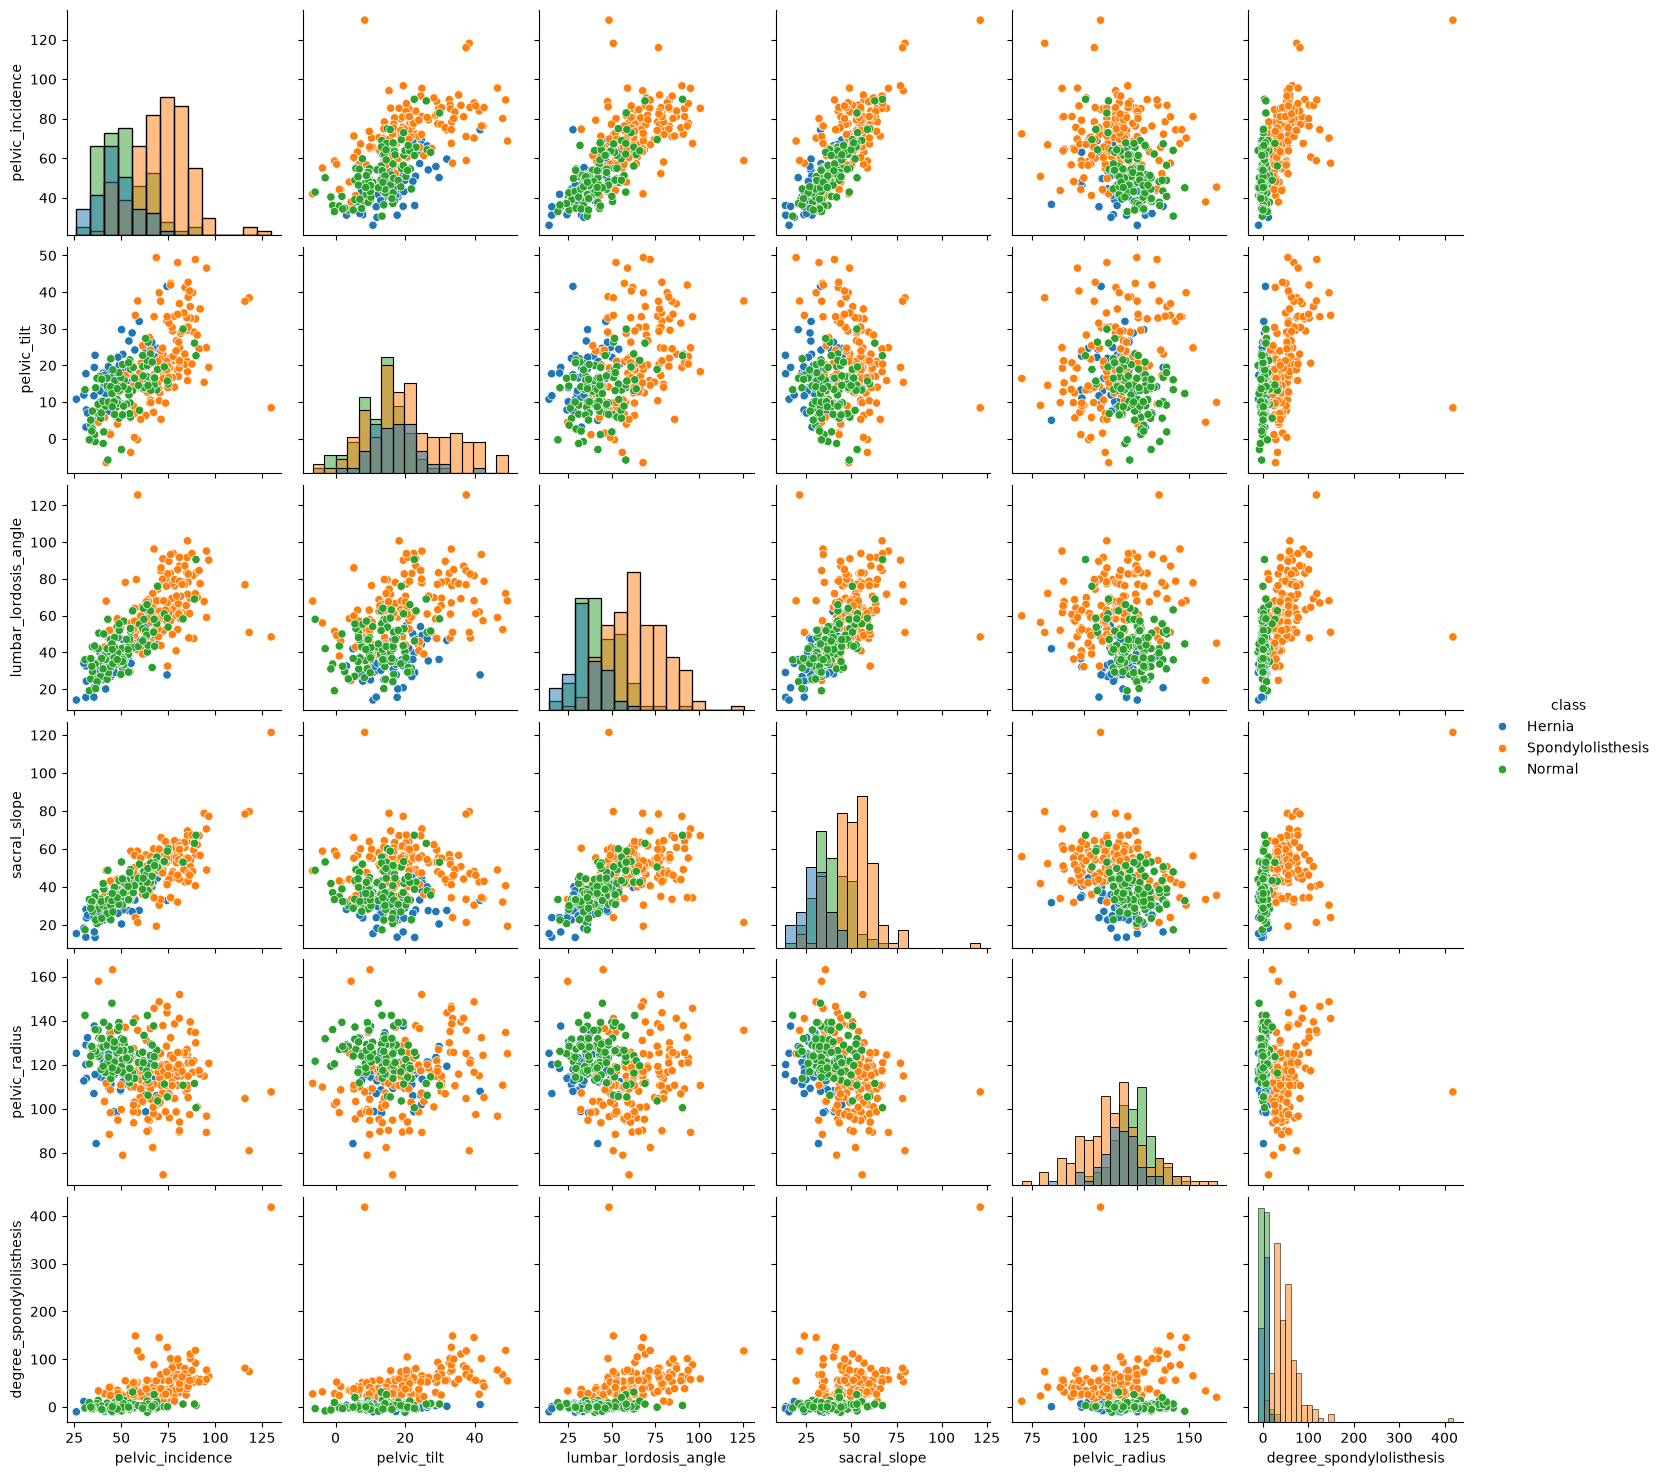

In [32]:
sns.pairplot(data1, hue="class",diag_kind="hist")
plt.show()



class
Spondylolisthesis    150
Normal               100
Hernia                60
Name: count, dtype: int64

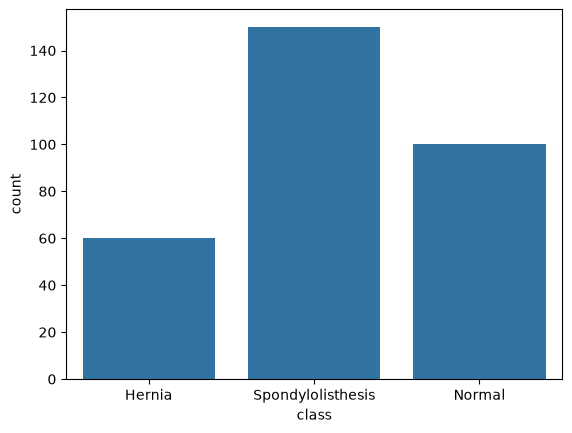

In [33]:
sns.countplot(x="class", data=data1)
data1.loc[:,'class'].value_counts()

2. **Classify with k-NN (20 minutes).** Split the data into training and test sets, train the classifier, and report accuracy. Select `k` using only training data (for example, cross-validation), then evaluate the chosen model on the test set. Predict a new example outside both sets. Complete the random forest comparison in the companion notebook.

In [48]:
# Select the best k value for the k-NN classifier
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.3, random_state=42, stratify=y)
knn = KNeighborsClassifier(n_neighbors = 5)
x,y = data1.loc[:,data1.columns != 'class'], data1.loc[:,'class']

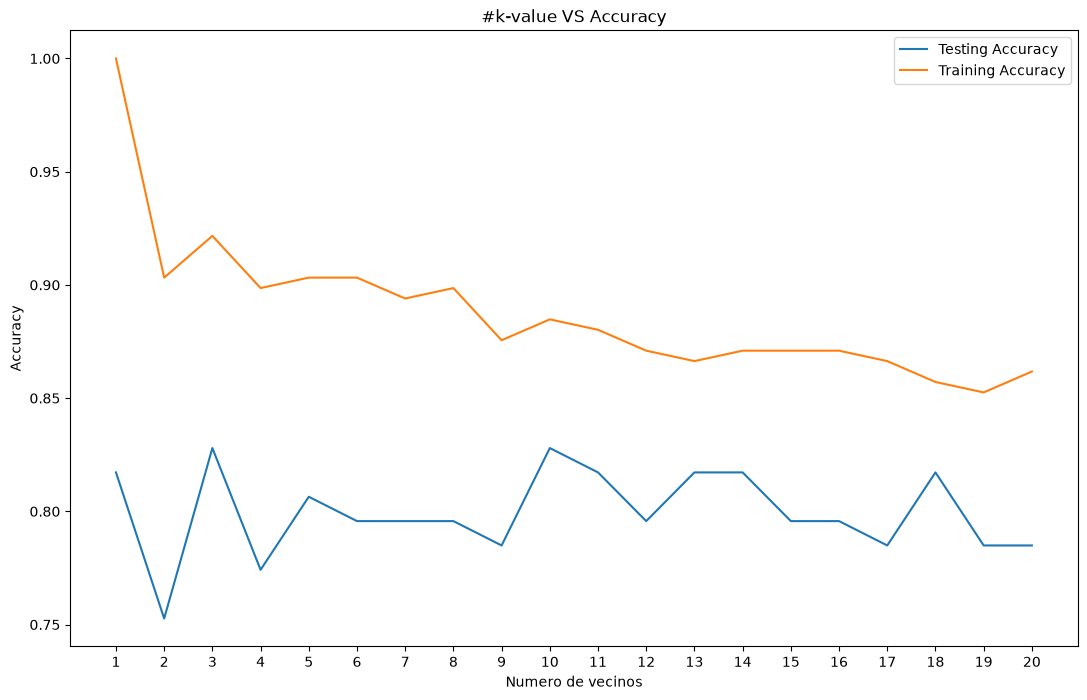

Best accuracy is 0.8279569892473119 with K = 3


In [50]:
# Fit a k-NN classifier to the training data
import numpy as np
# Model complexity
vecinos = np.arange(1, 21)
train_accuracy = []
test_accuracy = []
# Loop over different values of k
for i, k in enumerate(vecinos):
    knn = KNeighborsClassifier(n_neighbors=k)
    # Fit with knn
    knn.fit(x_train,y_train)
    #train accuracy
    train_accuracy.append(knn.score(x_train, y_train))
    # test accuracy
    test_accuracy.append(knn.score(x_test, y_test))

# Plot
plt.figure(figsize=[13,8])
plt.plot(vecinos, test_accuracy, label = 'Testing Accuracy')
plt.plot(vecinos, train_accuracy, label = 'Training Accuracy')
plt.legend()
plt.title('#k-value VS Accuracy')
plt.xlabel('Numero de vecinos')
plt.ylabel('Accuracy')
plt.xticks(vecinos)
plt.show()
print("Best accuracy is {} with K = {}".format(np.max(test_accuracy),1+test_accuracy.index(np.max(test_accuracy))))

In [51]:
# Fit a k-NN classifier to the training data
knn = KNeighborsClassifier(n_neighbors = 3)
knn.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['Hernia','Normal','Spondylolisthesis']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [52]:
predictions = knn.predict(x_test)

In [53]:
print(classification_report(y_test, predictions, zero_division=0))

                   precision    recall  f1-score   support

           Hernia       0.62      0.72      0.67        18
           Normal       0.76      0.73      0.75        30
Spondylolisthesis       0.98      0.93      0.95        45

         accuracy                           0.83        93
        macro avg       0.78      0.80      0.79        93
     weighted avg       0.84      0.83      0.83        93



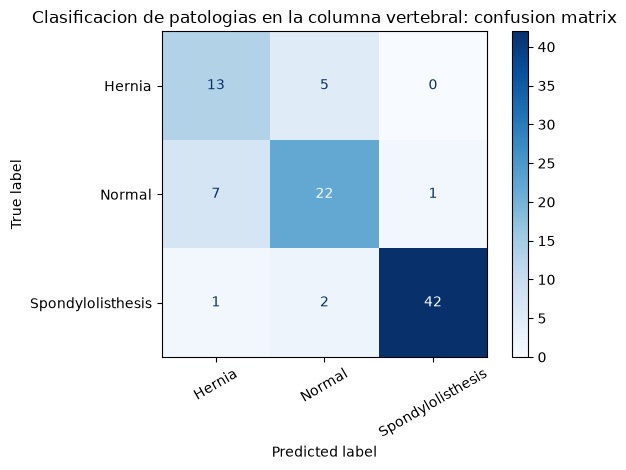

In [56]:
# Opción 1: Dejar que scikit-learn lo detecte automáticamente (Recomendado)
ConfusionMatrixDisplay.from_predictions(
    y_test, 
    predictions, 
    cmap="Blues"
)
plt.title("Clasificacion de patologias en la columna vertebral: confusion matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


3. **Present the dataset and process (30 minutes).** Explain decisions and results, and discuss possible improvements.


Write a brief explanation of the dataset, preprocessing steps, and model evaluation...


*   En el preprocesamiento se verifco el comportamiento de las variables independientes, las misma no en encuentran segadas, se verifico la cantidad de datos, el numero de variabes objetivos y se realizo un un pairplot con el proposito de identificar la formacion de las tres categorias.
*  En el modelamiento se realizo a partir de dividir el set de entrenamiento 70/30, para elegir el numero de K o vecinos mas cercanos se construyo un grafico que muestre la variacion del accuracy del modelo ajustado con los datos de entrenamiento y de testeo, el criterio de eleccion de k fue a partir del maximo accuracy 0.83 en testeo con un valor de k=3. 
*  El resultado del modelo arroja una alta sensibilidad al identificar los casos de Spondylolisthesis, condicion que puede resultar importante para un tratamiento para el paciente.

### Assessment
- Dataset source: 10%.
- Training/test split: 20%.
- Justification of the chosen `k`: 40%.
- Classification metrics: 30%.

### Deliverable
Submit the Jupyter notebook results as a PDF.